<a href="https://colab.research.google.com/github/marcelosantosjunior2027/IFOOD_GENAI_PORTIF-LIO/blob/main/Controle_Estoc%C3%A1stico_de_Estoque_(ROP_%26_EOQ).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

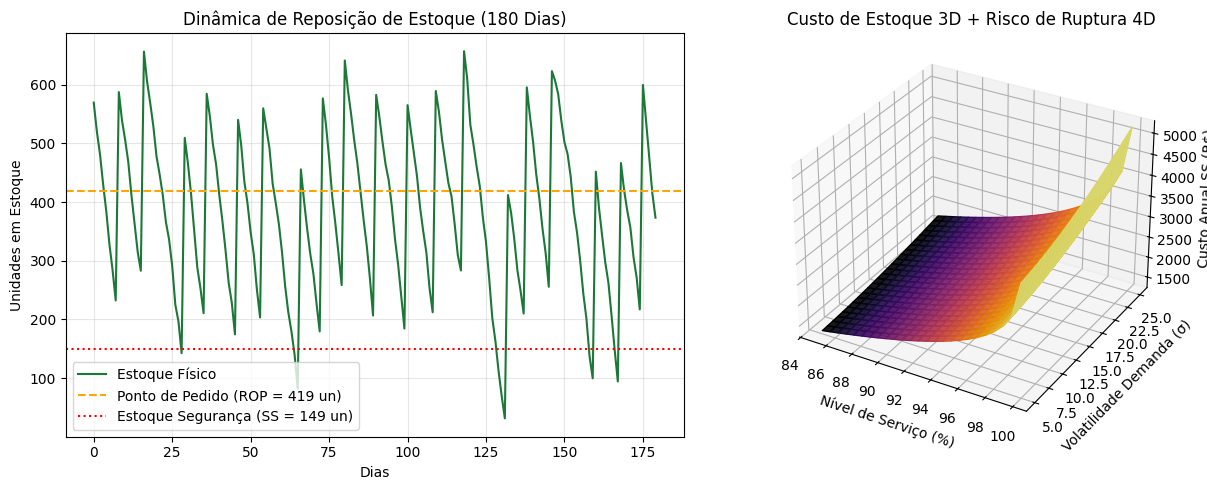

In [3]:
# AUTOR: MARCELO DE OLIVEIRA SANTOS JUNIOR
# PROJETO DE CONTROLE DE ESTOQUE


import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Parâmetros operacionais de um SKU crítico
d_mean, d_std = 45.0, 11.0      # Demanda: 45 un/dia ± 11
lt_mean, lt_std = 6.0, 1.5      # Lead time: 6 dias ± 1.5
service_level = 0.98            # Nível de serviço alvo: 98%
eoq = 420                       # Lote Econômico de Compra

z_score = norm.ppf(service_level)
safety_stock = z_score * np.sqrt(lt_mean * (d_std ** 2) + (d_mean ** 2) * (lt_std ** 2))
rop = (d_mean * lt_mean) + safety_stock

# 2. Simulação de 180 dias de operação
rng = np.random.default_rng(33)
days = 180
inventory = np.zeros(days)
inventory[0] = eoq + safety_stock
pending_orders = []  # (dia_chegada, quantidade)

for t in range(1, days):
    arrivals = sum(qty for day_arr, qty in pending_orders if day_arr == t)
    demand_today = max(0, rng.normal(d_mean, d_std))
    inventory[t] = max(0, inventory[t - 1] + arrivals - demand_today)

    in_transit = sum(qty for day_arr, qty in pending_orders if day_arr > t)
    if (inventory[t] + in_transit) <= rop:
        lead_time_real = max(2, int(round(rng.normal(lt_mean, lt_std))))
        pending_orders.append((t + lead_time_real, eoq))

fig = plt.figure(figsize=(13, 5))

# 2D: Dente de Serra do Estoque
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(inventory, color="#1b7837", lw=1.5, label="Estoque Físico")
ax1.axhline(rop, color="orange", linestyle="--", label=f"Ponto de Pedido (ROP = {rop:.0f} un)")
ax1.axhline(safety_stock, color="red", linestyle=":", label=f"Estoque Segurança (SS = {safety_stock:.0f} un)")
ax1.set_title("Dinâmica de Reposição de Estoque (180 Dias)")
ax1.set_xlabel("Dias")
ax1.set_ylabel("Unidades em Estoque")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 3D/4D: Trade-off do Custo de Manutenção vs Nível de Serviço
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
sl_grid = np.linspace(0.85, 0.999, 25)
std_grid = np.linspace(5.0, 25.0, 25)
SL, STD = np.meshgrid(sl_grid, std_grid)
SS_GRID = norm.ppf(SL) * np.sqrt(lt_mean * (STD ** 2) + (d_mean ** 2) * (lt_std ** 2))
HOLDING_COST = SS_GRID * 18.5  # R$ 18,50/un/ano de armazenagem
STOCKOUT_RISK = (1.0 - SL) * 100  # 4ª dimensão: Probabilidade de Ruptura (%)

sc = ax2.plot_surface(SL * 100, STD, HOLDING_COST, facecolors=plt.cm.inferno_r(STOCKOUT_RISK / STOCKOUT_RISK.max()), alpha=0.9)
ax2.set_title("Custo de Estoque 3D + Risco de Ruptura 4D")
ax2.set_xlabel("Nível de Serviço (%)")
ax2.set_ylabel("Volatilidade Demanda (σ)")
ax2.set_zlabel("Custo Anual SS (R$)")

plt.tight_layout()
plt.show()